# 1. Import Library

Pada tahap ini dilakukan pemanggilan beberapa library Python
yang digunakan untuk membantu proses analisis dan pengolahan data.

Library yang digunakan meliputi:
- Pandas: mengolah dan memanipulasi data dalam bentuk DataFrame.
- NumPy: melakukan operasi numerik dan perhitungan matematis.
- Matplotlib: membuat visualisasi data seperti histogram dan grafik.
- Seaborn: membuat visualisasi statistik seperti boxplot dan heatmap.
- Scikit-learn: membantu proses preprocessing, khususnya feature scaling.

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, MinMaxScaler

# 2. Memuat Dataset

Tahap ini dilakukan untuk membaca dataset yang akan digunakan
dalam penelitian.

Dataset yang digunakan adalah Bank Transaction Dataset for
Fraud Detection yang diperoleh dari Kaggle.

In [26]:
df = pd.read_csv("bank_transactions_data_2.csv")

df.head()

,IDTransaksi,IDRekening,JumlahNominalTransaksi,TanggalTransaksi,JenisTransaksi,Lokasi,IDPerangkat,AlamatIP,IDPedagang,SaluranTransaksi,UsiaNasabah,PekerjaanNasabah,DurasiTransaksi,JumlahPercobaanLogin,SaldoRekening,TanggalTransaksiSebelumnya
0,TX000001,AC00128,14.09,2023-04-11 16:29:14,Debit,San Diego,D000380,162.198.218.92,M015,ATM,70,Doctor,81,1,5112.21,2024-11-04 08:08:08
1,TX000002,AC00455,376.24,2023-06-27 16:44:19,Debit,Houston,D000051,13.149.61.4,M052,ATM,68,Doctor,141,1,13758.91,2024-11-04 08:09:35
2,TX000003,AC00019,126.29,2023-07-10 18:16:08,Debit,Mesa,D000235,215.97.143.157,M009,Online,19,Student,56,1,1122.35,2024-11-04 08:07:04
3,TX000004,AC00070,184.50,2023-05-05 16:32:11,Debit,Raleigh,D000187,200.13.225.150,M002,Online,26,Student,25,1,8569.06,2024-11-04 08:09:06
4,TX000005,AC00411,13.45,2023-10-16 17:51:24,Credit,Atlanta,D000308,65.164.3.100,M091,Online,26,Student,198,1,7429.40,2024-11-04 08:06:39


# 3. Data Understanding

## 3.1 Memahami Struktur Dataset

Tahap ini bertujuan untuk mengetahui gambaran umum dataset,
meliputi jumlah baris, jumlah kolom, nama atribut, tipe data,
serta informasi jumlah data yang tersedia pada setiap kolom.

Pemahaman terhadap struktur dataset diperlukan untuk mengetahui
karakteristik data dan menentukan proses pengolahan yang sesuai.

In [27]:
print("Ukuran dataset : ", df.shape)

df.info()

print(df.columns.tolist())

Ukuran dataset :  (2512, 16)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2512 entries, 0 to 2511
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   IDTransaksi                 2512 non-null   object 
 1   IDRekening                  2512 non-null   object 
 2   JumlahNominalTransaksi      2512 non-null   float64
 3   TanggalTransaksi            2512 non-null   object 
 4   JenisTransaksi              2512 non-null   object 
 5   Lokasi                      2512 non-null   object 
 6   IDPerangkat                 2512 non-null   object 
 7   AlamatIP                    2512 non-null   object 
 8   IDPedagang                  2512 non-null   object 
 9   SaluranTransaksi            2512 non-null   object 
 10  UsiaNasabah                 2512 non-null   int64  
 11  PekerjaanNasabah            2512 non-null   object 
 12  DurasiTransaksi             2512 non-null   int64  
 13  Juml

## 3.2 Statistik Deskriptif

Statistik deskriptif dilakukan untuk memperoleh gambaran
karakteristik data berdasarkan nilai statistiknya.

Analisis mencakup nilai rata-rata (mean), standar deviasi,
nilai minimum, kuartil, median, dan maksimum.

Hasil analisis digunakan untuk memahami rentang nilai,
persebaran data, serta perbedaan karakteristik antaratribut.

In [28]:
df.describe()

,JumlahNominalTransaksi,UsiaNasabah,DurasiTransaksi,JumlahPercobaanLogin,SaldoRekening
count,2512.000000,2512.000000,2512.000000,2512.000000,2512.000000
mean,297.593778,44.673965,119.643312,1.124602,5114.302966
std,291.946243,17.792198,69.963757,0.602662,3900.942499
min,0.260000,18.000000,10.000000,1.000000,101.250000
25%,81.885000,27.000000,63.000000,1.000000,1504.370000
50%,211.140000,45.000000,112.500000,1.000000,4735.510000
75%,414.527500,59.000000,161.000000,1.000000,7678.820000
max,1919.110000,80.000000,300.000000,5.000000,14977.990000


In [29]:
df.describe(include=['O'])

,IDTransaksi,IDRekening,TanggalTransaksi,JenisTransaksi,Lokasi,IDPerangkat,AlamatIP,IDPedagang,SaluranTransaksi,PekerjaanNasabah,TanggalTransaksiSebelumnya
count,2512,2512,2512,2512,2512,2512,2512,2512,2512,2512,2512
unique,2512,495,2512,2,43,681,592,100,3,4,360
top,TX000001,AC00460,2023-04-11 16:29:14,Debit,Fort Worth,D000548,200.136.146.93,M026,Branch,Student,2024-11-04 08:09:17
freq,1,12,1,1944,70,9,13,45,868,657,16


## 3.3 Pemeriksaan Missing Values

Missing values merupakan kondisi ketika suatu atribut
memiliki nilai yang kosong atau tidak tersedia.

Pemeriksaan dilakukan untuk mengetahui jumlah dan persentase
nilai kosong pada setiap atribut.

Hasil pemeriksaan menjadi dasar untuk menentukan apakah
diperlukan penanganan missing values, seperti penghapusan
data atau imputasi menggunakan nilai statistik tertentu.

In [30]:
print("jumlah missing value perkolom : ")
print(df.isnull().sum())

jumlah missing value perkolom : 
IDTransaksi                   0
IDRekening                    0
JumlahNominalTransaksi        0
TanggalTransaksi              0
JenisTransaksi                0
Lokasi                        0
IDPerangkat                   0
AlamatIP                      0
IDPedagang                    0
SaluranTransaksi              0
UsiaNasabah                   0
PekerjaanNasabah              0
DurasiTransaksi               0
JumlahPercobaanLogin          0
SaldoRekening                 0
TanggalTransaksiSebelumnya    0
dtype: int64


## 3.4 Pemeriksaan Data Duplikat

Data duplikat merupakan data yang memiliki kesamaan pada
seluruh atribut atau baris tertentu.

Pemeriksaan dilakukan untuk mengetahui apakah terdapat
pencatatan data yang berulang.

Data duplikat perlu diperhatikan karena dapat menyebabkan
perhitungan statistik menjadi tidak akurat dan memengaruhi
hasil analisis clustering.

In [31]:
print("Jumlah data duplikat :")
print(df.duplicated().sum())

Jumlah data duplikat :
0


## 3.5 Analisis Distribusi Data

Analisis distribusi dilakukan untuk memahami pola persebaran
nilai pada setiap atribut.

Pada atribut numerik, distribusi diamati menggunakan histogram.
Sementara itu, atribut kategorikal dianalisis menggunakan
diagram batang (bar chart).

Visualisasi ini membantu mengidentifikasi pola distribusi,
ketidakseimbangan kategori, serta kemungkinan kemencengan
distribusi data (skewness).

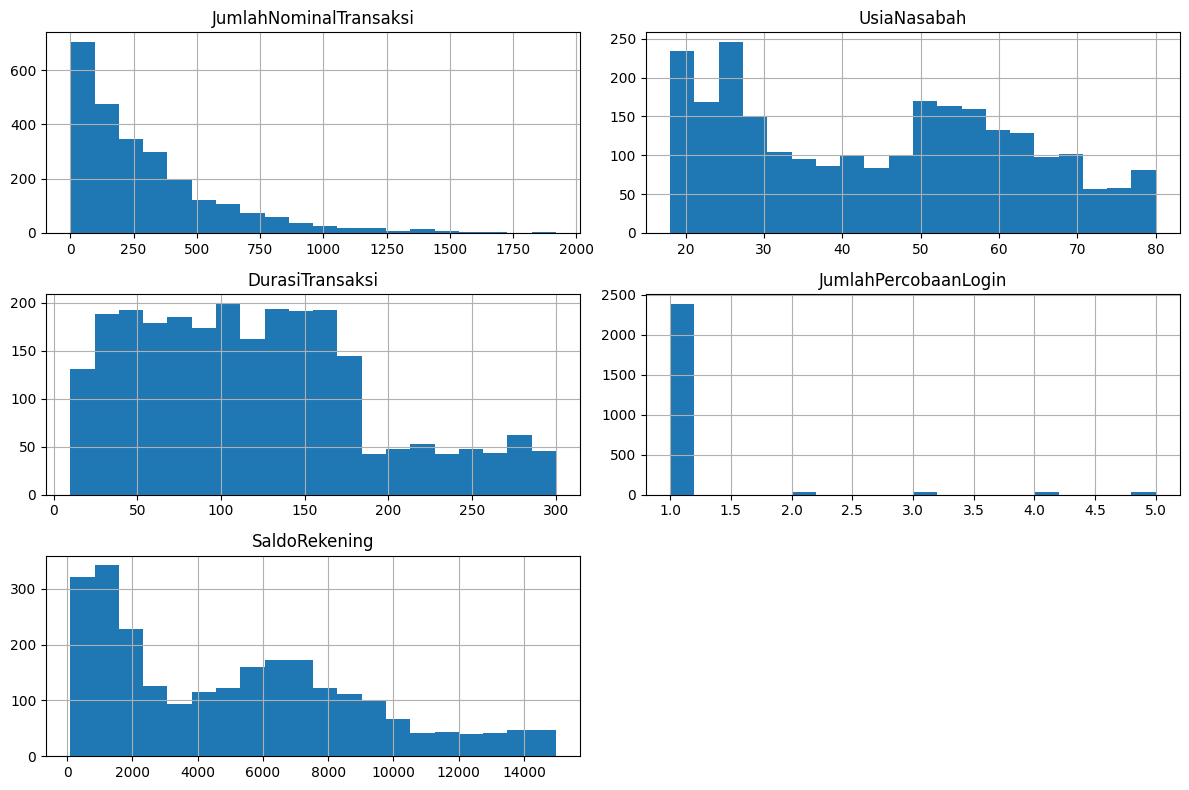

In [32]:
numerical_columns = [
    "JumlahNominalTransaksi",
    "UsiaNasabah",
    "DurasiTransaksi",
    "JumlahPercobaanLogin",
    "SaldoRekening"
]


df[numerical_columns].hist(figsize=(12, 8), bins=20)
plt.tight_layout()
plt.show()

## 3.5 Identifikasi Outlier

Outlier merupakan nilai yang memiliki karakteristik berbeda
secara signifikan dibandingkan sebagian besar data lainnya.

Identifikasi outlier dilakukan menggunakan metode
Interquartile Range (IQR), yaitu metode yang menggunakan
jarak antara kuartil pertama (Q1) dan kuartil ketiga (Q3).

Batas bawah dan batas atas ditentukan menggunakan rumus:

IQR = Q3 - Q1

Lower Bound = Q1 - 1.5 × IQR

Upper Bound = Q3 + 1.5 × IQR

Nilai yang berada di luar batas tersebut ditandai sebagai
kandidat outlier. Hasil identifikasi digunakan untuk
mempertimbangkan perlakuan terhadap outlier pada tahap
Data Preparation.

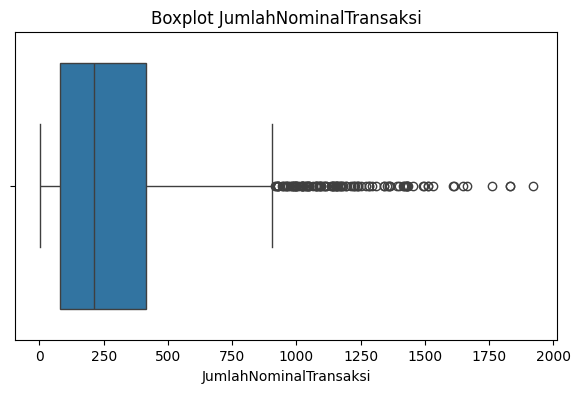

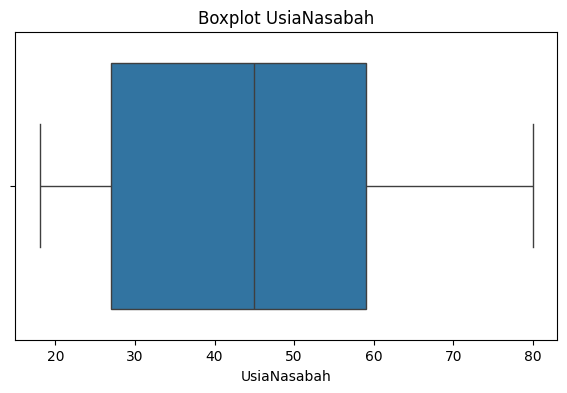

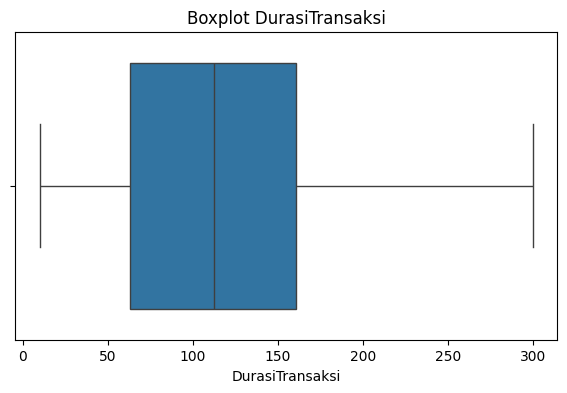

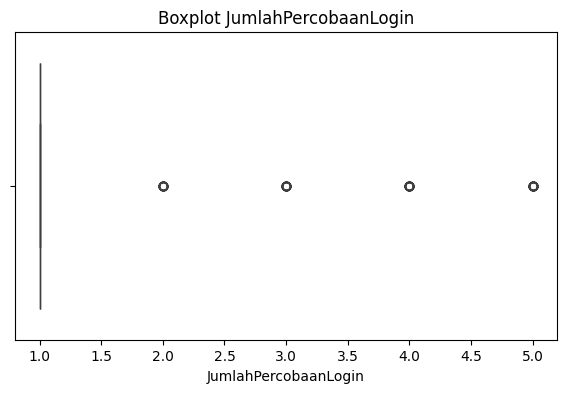

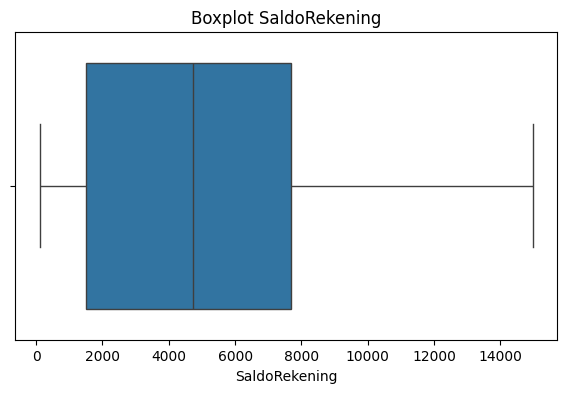

In [33]:
for col in numerical_columns:
    plt.figure(figsize=(7, 4))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot {col}")
    plt.show()


## 3.6 Analisis Korelasi

Analisis korelasi dilakukan untuk mengetahui hubungan
antaratribut numerik.

Korelasi menunjukkan arah dan kekuatan hubungan linear
antara dua variabel.

Hasil analisis divisualisasikan menggunakan correlation
heatmap untuk membantu mengidentifikasi atribut yang
memiliki hubungan kuat.

Informasi ini dapat menjadi pertimbangan dalam proses
pemilihan fitur (feature selection).

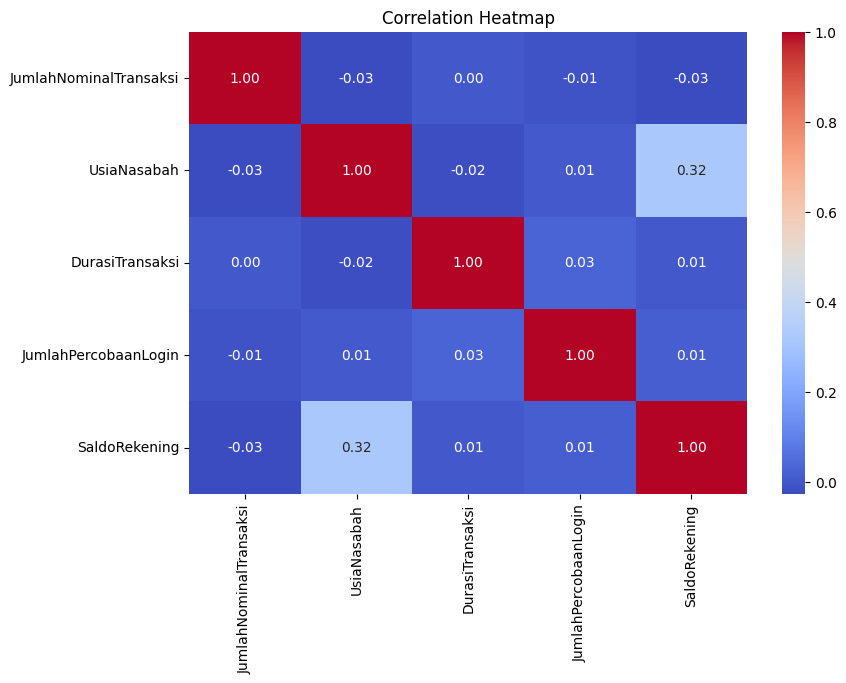

In [34]:
correlation = df[numerical_columns].corr()

plt.figure(figsize=(9, 6))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

# 4. Data Prepatarion

## 4.1 Data Cleaning

Data Cleaning merupakan proses membersihkan dataset dari
permasalahan kualitas data yang ditemukan pada tahap
Data Understanding.

Proses ini dilakukan agar data yang digunakan memiliki
kualitas yang lebih baik sebelum memasuki tahap preprocessing.

Beberapa proses yang diperhatikan meliputi:

1. Menghapus data duplikat apabila ditemukan.
2. Menangani missing values apabila terdapat nilai kosong.
3. Memeriksa konsistensi data, termasuk format tanggal dan
   nilai atribut.
4. Mempertimbangkan penanganan outlier berdasarkan
   karakteristik dan kebutuhan penelitian.

Tidak semua data yang teridentifikasi sebagai outlier
harus dihapus. Penanganannya perlu mempertimbangkan
relevansi nilai tersebut terhadap tujuan clustering.

### 1. Penanganan data duplikat

Berdasarkan hasil data understanding, tidak ada data duplikat yg ditemukan

### 2. Missing value 

Tidak ada missing value yang ditemukan

In [35]:
### 2. Missing value 

### 3. Memeriksa konsistensi data, termasuk format tanggal dan nilai atribut.

In [36]:
# Daftar kolom kategorikal utama, ini fitur2 yg kita pakai
cat_cols = ['JenisTransaksi', 'SaluranTransaksi', 'Lokasi', 'PekerjaanNasabah']

print("Pengecekan Nilai Unik pada Atribut Kategorikal")
for col in cat_cols:
    print(f"\nKolom: {col}")

    print(df[col].unique())

Pengecekan Nilai Unik pada Atribut Kategorikal

Kolom: JenisTransaksi
['Debit' 'Credit']

Kolom: SaluranTransaksi
['ATM' 'Online' 'Branch']

Kolom: Lokasi
['San Diego' 'Houston' 'Mesa' 'Raleigh' 'Atlanta' 'Oklahoma City'
 'Seattle' 'Indianapolis' 'Detroit' 'Nashville' 'Albuquerque' 'Memphis'
 'Louisville' 'Denver' 'Austin' 'Columbus' 'Los Angeles' 'Las Vegas'
 'Fort Worth' 'Miami' 'Milwaukee' 'Baltimore' 'New York' 'San Francisco'
 'San Jose' 'San Antonio' 'Philadelphia' 'Charlotte' 'Tucson' 'Chicago'
 'Sacramento' 'Kansas City' 'Omaha' 'Virginia Beach' 'Dallas' 'Boston'
 'Jacksonville' 'Phoenix' 'Washington' 'El Paso' 'Colorado Springs'
 'Fresno' 'Portland']

Kolom: PekerjaanNasabah
['Doctor' 'Student' 'Retired' 'Engineer']


### 4. Pembersihan spasi yg tidak sesuai

## 4.2 Data Preprocessing

Data Preprocessing merupakan proses mengubah data yang
telah dibersihkan agar dapat digunakan oleh algoritma
machine learning.

Pada penelitian ini, preprocessing disesuaikan dengan
karakteristik algoritma K-Means dan Hierarchical Clustering
yang menggunakan perhitungan jarak antarobservasi.

Tahapan preprocessing yang dipertimbangkan meliputi:

1. Penentuan unit analisis.
2. Pemilihan dan penyesuaian tipe data.
3. Encoding atribut kategorikal apabila digunakan.
4. Feature scaling untuk menyamakan skala antaratribut.

Proses preprocessing bertujuan untuk memastikan bahwa
setiap fitur dapat digunakan secara tepat dalam perhitungan
jarak pada proses clustering.

### 4.2.1 Penentuan Unit Analisis

Unit analisis merupakan objek yang akan dikelompokkan
oleh algoritma clustering.

Pada penelitian ini, unit analisis perlu ditentukan
sebagai transaksi atau akun nasabah.

Penentuan ini penting karena satu AccountID dapat memiliki
lebih dari satu catatan transaksi dan ditemukan
ketidakkonsistenan nilai CustomerAge pada beberapa akun.

Oleh karena itu, pembentukan unit analisis harus
mempertimbangkan konsistensi identitas akun agar hasil
segmentasi tidak menghasilkan profil yang keliru.

In [37]:
# 1. Melihat total keseluruhan baris dan total unik akun nasabah (AccountID)
total_transaksi = len(df)
total_akun = df['IDRekening'].nunique() # Sesuaikan 'IDRekening' dengan nama kolom ID akun kamu

print(f"Total Baris (Catatan Transaksi): {total_transaksi}")
print(f"Total Akun Unik (AccountID): {total_akun}")
print(f"Rata-rata transaksi per akun: {total_transaksi / total_akun:.2f}")

# 2. Mengecek apakah ada AccountID yang memiliki inkonsistensi 'UsiaNasabah' (CustomerAge)
# Caranya: menghitung jumlah nilai unik usia untuk setiap IDRekening
age_check = df.groupby('IDRekening')['UsiaNasabah'].nunique()
inconsistent_accounts = age_check[age_check > 1]

print(f"\nJumlah akun dengan inkonsistensi usia nasabah: {len(inconsistent_accounts)}")

if len(inconsistent_accounts) > 0:
    print("Contoh IDRekening yang memiliki variasi usia berbeda:")
    print(inconsistent_accounts.head())
else:
    print("Aman! Semua akun memiliki catatan usia nasabah yang konsisten.")

Total Baris (Catatan Transaksi): 2512
Total Akun Unik (AccountID): 495
Rata-rata transaksi per akun: 5.07

Jumlah akun dengan inkonsistensi usia nasabah: 470
Contoh IDRekening yang memiliki variasi usia berbeda:
IDRekening
AC00001    2
AC00002    7
AC00003    5
AC00004    9
AC00005    9
Name: UsiaNasabah, dtype: int64


### 4.2.2 Encoding Data Kategorikal

Encoding merupakan proses mengubah atribut kategorikal
menjadi representasi numerik agar dapat diproses oleh
algoritma machine learning.

Apabila atribut seperti TransactionType, Channel, dan
CustomerOccupation digunakan sebagai fitur, encoding
dapat dilakukan menggunakan metode One-Hot Encoding.

Metode ini merepresentasikan setiap kategori menjadi
kolom indikator bernilai 0 atau 1.

Encoding hanya dilakukan terhadap atribut kategorikal
yang dipilih untuk digunakan dalam clustering.

### 1. One-Hot Enoding untuk JenisTransaksi

In [40]:
df_encoded_jenis = pd.get_dummies(df['JenisTransaksi'], prefix='Tipe')

print("Hasil Encoding - JenisTransaksi:")
display(df_encoded_jenis.head())

Hasil Encoding - JenisTransaksi:


,Tipe_Credit,Tipe_Debit
0,False,True
1,False,True
2,False,True
3,False,True
4,True,False


### 2. One-Hot Encoding Saluran Transaksi

In [46]:
df_encoded_saluran = pd.get_dummies(df['SaluranTransaksi'], prefix='Kanal')

print("Hasil Encoding - SaluranTransaksi:")
display(df_encoded_saluran.head())

Hasil Encoding - SaluranTransaksi:


,Kanal_ATM,Kanal_Branch,Kanal_Online
0,True,False,False
1,True,False,False
2,False,False,True
3,False,False,True
4,False,False,True


### 4.2.3 Agregasi 

In [45]:
df_lengkap = pd.concat([df, df_encoded_jenis, df_encoded_saluran], axis=1)

print("Total baris transaksi awal:", len(df_lengkap))
print("Jumlah akun unik (IDRekening):", df_lengkap['IDRekening'].nunique())

# 2. Lakukan Agregasi menggunakan df_lengkap
df_agregasi = df_lengkap.groupby('IDRekening').agg({
    # Demografi: Mengatasi inkonsistensi usia dengan modus
    'UsiaNasabah': lambda x: x.mode()[0],
    
    # Profiling: Disimpan untuk analisis segmen
    'PekerjaanNasabah': 'first',
    
    # Fitur Numerik & Agregasinya
    'JumlahNominalTransaksi': ['sum', 'mean'], 
    'IDTransaksi': 'count',                        # Menghitung frekuensi transaksi per akun
    'DurasiTransaksi': 'mean',                      
    'JumlahPercobaanLogin': 'mean',             
    'SaldoRekening': 'mean',
    
    # Fitur Hasil Encoding (Dijumlahkan per akun)
    'Tipe_Debit': 'sum',
    'Tipe_Credit': 'sum',
    'Kanal_ATM': 'sum',
    'Kanal_Branch': 'sum',
    'Kanal_Online': 'sum'
}).reset_index()

# 3. Merapikan nama kolom hasil multi-index
df_agregasi.columns = [
    'ID_Rekening', 'Usia_Nasabah', 'Pekerjaan_Nasabah', 
    'Total_Nominal_Transaksi', 'Rata_Rata_Nominal', 
    'Frekuensi_Transaksi', 'Rata_Rata_Durasi', 
    'Rata_Rata_Login', 'Rata_Rata_Saldo',
    'Frekuensi_Debit', 'Frekuensi_Kredit',
    'Kanal_ATM', 'Kanal_Branch', 'Kanal_Online'
]

# 4. Validasi hasil akhir (harus 495 baris)
print("Total baris setelah agregasi:", len(df_agregasi))
display(df_agregasi.head())

Total baris transaksi awal: 2512
Jumlah akun unik (IDRekening): 495
Total baris setelah agregasi: 495


,ID_Rekening,Usia_Nasabah,Pekerjaan_Nasabah,Total_Nominal_Transaksi,Rata_Rata_Nominal,Frekuensi_Transaksi,Rata_Rata_Durasi,Rata_Rata_Login,Rata_Rata_Saldo,Frekuensi_Debit,Frekuensi_Kredit,Kanal_ATM,Kanal_Branch,Kanal_Online
0,AC00001,25,Student,260.76,130.380000,2,107.500000,1.000000,2915.160000,2,0,0,1,1
1,AC00002,23,Retired,2056.21,293.744286,7,109.857143,1.142857,4480.421429,6,1,2,3,2
2,AC00003,26,Doctor,1266.34,253.268000,5,49.200000,1.000000,7329.568000,4,1,4,0,1
3,AC00004,25,Retired,2180.08,242.231111,9,104.333333,1.000000,3340.956667,8,1,2,4,3
4,AC00005,21,Engineer,3131.77,347.974444,9,145.111111,1.000000,4457.837778,8,1,0,7,2


### 4.2.4 Feature Scaling

Feature Scaling merupakan proses menyamakan rentang
skala antarfitur agar atribut dengan nilai numerik besar
tidak mendominasi perhitungan jarak.

Tahap ini penting karena K-Means dan Hierarchical
Clustering menggunakan perhitungan jarak untuk
menentukan kemiripan antarobservasi.

Metode yang digunakan dalam penelitian ini adalah
StandardScaler.

StandardScaler mengubah nilai setiap fitur berdasarkan
rata-rata dan standar deviasi sehingga data memiliki
rata-rata mendekati 0 dan standar deviasi mendekati 1.

## 4.3 Feature Selection

Feature Selection merupakan proses memilih atribut
yang paling relevan dengan tujuan penelitian.

Tahap ini bertujuan untuk mengurangi penggunaan atribut
yang tidak memberikan informasi penting, menghindari
penggunaan identitas sebagai fitur, serta mengurangi
potensi redundansi antarvariabel.

Pemilihan fitur mempertimbangkan beberapa aspek:

1. Relevansi atribut terhadap karakteristik transaksi
   dan finansial.
2. Ketersediaan serta kualitas data.
3. Hasil analisis distribusi dan korelasi.
4. Kemungkinan hubungan yang terlalu kuat antarfitur.
5. Kesesuaian fitur dengan tujuan segmentasi.

Atribut identitas seperti TransactionID, AccountID,
DeviceID, IP Address, dan MerchantID tidak digunakan
sebagai fitur clustering.

Fitur akhir ditentukan berdasarkan hasil analisis dan
unit analisis yang telah dipilih.

## 4.4 Final Dataset

Tahap ini merupakan tahap akhir Data Preparation.

Dataset yang telah melalui proses cleaning, preprocessing,
dan feature selection diperiksa kembali untuk memastikan
bahwa data telah siap digunakan dalam proses clustering.

Pemeriksaan meliputi:
- Jumlah baris dan kolom.
- Atribut yang digunakan.
- Missing values.
- Tipe data.
- Hasil feature scaling.

Dataset akhir kemudian disimpan dan digunakan sebagai
input untuk pemodelan menggunakan K-Means dan
Hierarchical Clustering.